In [32]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "pandas", "numpy", "matplotlib", "seaborn"])
print("Packages installed successfully!")

Packages installed successfully!


In [33]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
# cleaning trailing spaces
df.columns = df.columns.str.strip()

# verify it was cleaned
print([col in df.columns if 'Delay' in col else False for col in df.columns])

[False, False, False, False, False, False, False, False, False, True, True, True, True, True]


In [35]:
all_files = glob.glob("*.csv")

use_cols = [
    'FlightDate', 'Reporting_Airline', 'Origin', 'DEST', 
    'CRSDepTime','DEP_DELAY', 'CRSArrTime', 'ARR_DELAY',
    'TaxiOut', 'TaxiIn', 'AirTime', 'Cancelled', 
    'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay'
    ]

df_list = []
for file in all_files:
    temp_df = pd.read_csv(file, usecols=lambda c: c in use_cols)
    df_list.append(temp_df)

df = pd.concat(df_list, ignore_index=True)
print(f"Combined datasets across all months! Total rows: {len(df)}")

Combined datasets across all months! Total rows: 7001619


In [48]:
# 1. Print all available columns to see what we are working with
print("All columns currently in df:", df.columns.tolist())

# 2. Filter out cancelled flights and clean CRSDepTime
active_flights = df[df['Cancelled'] == 0].copy()
active_flights['CRSDepTime_clean'] = active_flights['CRSDepTime'].astype(str).str.split('.').str[0].str.zfill(4)
active_flights['DepHour'] = pd.to_numeric(active_flights['CRSDepTime_clean'].str[:2], errors='coerce')

# 3. Choose your hub
target_hub = 'DFW'
hub_flights = active_flights[active_flights['Origin'] == target_hub].copy()
print(f"\nTotal active departures from {target_hub}: {len(hub_flights):,}")

All columns currently in df: ['FlightDate', 'Reporting_Airline', 'Origin', 'CRSDepTime', 'TaxiOut', 'TaxiIn', 'CRSArrTime', 'Cancelled', 'AirTime', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']

Total active departures from DFW: 307,148


In [49]:
#Extract Departure hours and Calculate queue wait times
df.columns = df.columns.str.strip()

active_flights  = df[df['Cancelled'] == 0].copy()

active_flights['CRSDepTime_clean'] = active_flights['CRSDepTime'].astype(str).str.split('.').str[0].str.zfill(4)
active_flights['DepHour'] = pd.to_numeric(active_flights['CRSDepTime_clean'].str[:2], errors='coerce')

#Flight hubs chosen based on size and number of flights (Busiest airports in the US)
target_hub = 'DFW' # Dallas Fort Worth International Airport
hub_flights = active_flights[active_flights['Origin'] == target_hub].copy()
print(f"Total active departures from {target_hub}: {len(hub_flights)}")

hub_flights['TaxiOut_clean'] = pd.to_numeric(hub_flights['TaxiOut'], errors='coerce').fillna(0)

# Get Arrival rate (lambda) and average wait time (W)
hourly_wait = hub_flights.groupby('DepHour').agg(
    ArrivalRate = ('FlightDate', 'count'), # Lambda
    AvgWaitTime = ('TaxiOut_clean', 'mean') # W
).reset_index()

print("Hourly queueing summary calculated for flights departing from the hub.")
display(hourly_wait.head(10))

Total active departures from DFW: 307148
Hourly queueing summary calculated for flights departing from the hub.


,DepHour,ArrivalRate,AvgWaitTime
0,5,3845,15.859298
1,6,4753,17.345887
2,7,20685,20.105004
3,8,30687,21.623163
4,9,10955,18.344044
5,10,24835,21.301188
6,11,12758,18.006741
7,12,24908,19.546652
8,13,12272,16.974576
9,14,21166,18.412312


<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/var/folders/7n/_bph8q656mz7td_1n564qw_40000gn/T/ipykernel_52305/1263134911.py:29: SyntaxWarning: invalid escape sequence '\l'
  label='Flight Volume (Arrival Rate $\lambda$)'


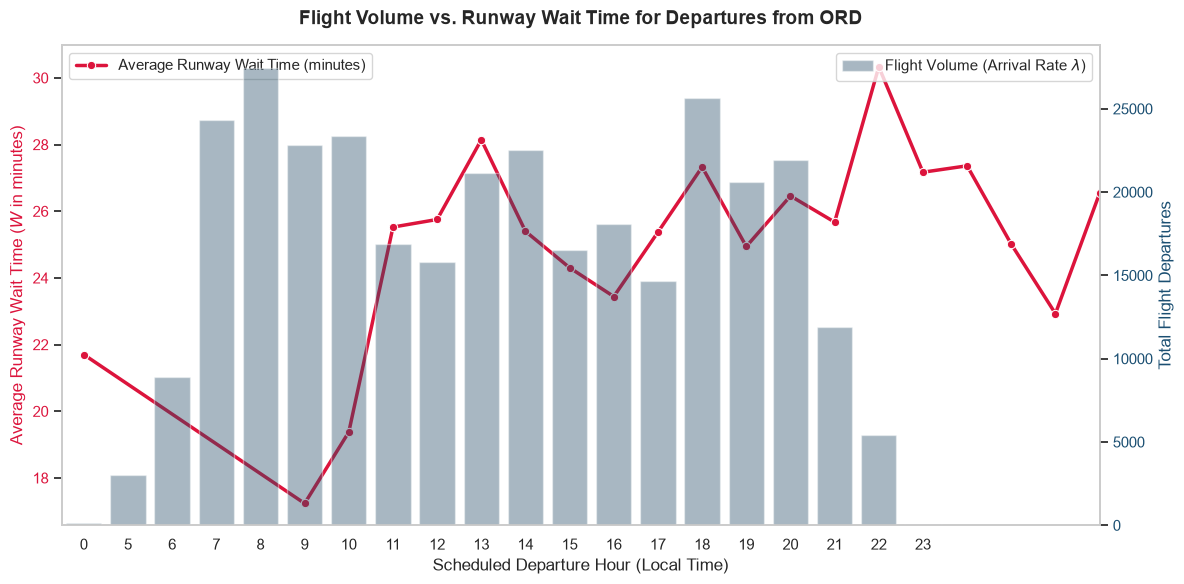

In [63]:
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=hourly_wait, 
    x='DepHour', 
    y='AvgWaitTime', 
    marker = 'o',
    color = 'crimson',
    ax=ax1,
    linewidth=2.5,
    label='Average Runway Wait Time (minutes)'
)

ax1.set_title(f'Flight Volume vs. Runway Wait Time for Departures from {target_hub}', fontsize=14,
    fontweight='bold', pad=15)
ax1.set_xlabel('Scheduled Departure Hour (Local Time)', fontsize=12)
ax1.set_ylabel('Average Runway Wait Time ($W$ in minutes)', color='crimson', fontsize=12)
ax1.tick_params(axis='y', labelcolor='crimson')

ax2 = ax1.twinx()
sns.barplot(
    data=hourly_wait, 
    x='DepHour', 
    y='ArrivalRate', 
    alpha=0.4, 
    ax=ax2, 
    color='#1B4F72', 
    label='Flight Volume (Arrival Rate $\lambda$)'
)

ax2.set_ylabel('Total Flight Departures', color='#1B4F72', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#1B4F72')
ax2.grid(False)
ax1.grid(False)

plt.xticks(range(0, 24))
fig.tight_layout()
plt.show()

In [55]:
peak_hour_row = hourly_wait.loc[hourly_wait['ArrivalRate'].idxmax()]
lambda_peak = peak_hour_row['ArrivalRate']
peak_dep_hour = peak_hour_row['DepHour']
avg_wait_peak = peak_hour_row['AvgWaitTime']

print(f"Peak Departure Hour at DFW: {int(peak_dep_hour)}:00")
print(f"Peak Arrival Rate (lambda): {lambda_peak:,} flights/hour")
print(f"Average Wait Time at Peak: {avg_wait_peak:.2f} minutes")

c_runways = 3

runway_capacity_per_hour = 40 # standard FAA optimal throughput per runway
total_system_capacity = c_runways * runway_capacity_per_hour

rho_peak = lambda_peak / total_system_capacity
print(f"\nEstimated Peak System Capacity ({c_runways} runways @ {runway_capacity_per_hour}/hr): {total_system_capacity} departures/hr")
print(f"Calculated Traffic Intensity (Rho): {rho_peak:.2f} (Note: > 1.0 indicates oversaturated queue)")

Peak Departure Hour at DFW: 8:00
Peak Arrival Rate (lambda): 30,687.0 flights/hour
Average Wait Time at Peak: 21.62 minutes

Estimated Peak System Capacity (3 runways @ 40/hr): 120 departures/hr
Calculated Traffic Intensity (Rho): 255.72 (Note: > 1.0 indicates oversaturated queue)


<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:44: SyntaxWarning: invalid escape sequence '\l'
/var/folders/7n/_bph8q656mz7td_1n564qw_40000gn/T/ipykernel_52305/3217269372.py:44: SyntaxWarning: invalid escape sequence '\l'
  label='Flight Volume (Arrival Rate $\lambda$)'



Now analyzing departures from ORD...
Total active departures from ORD: 321372


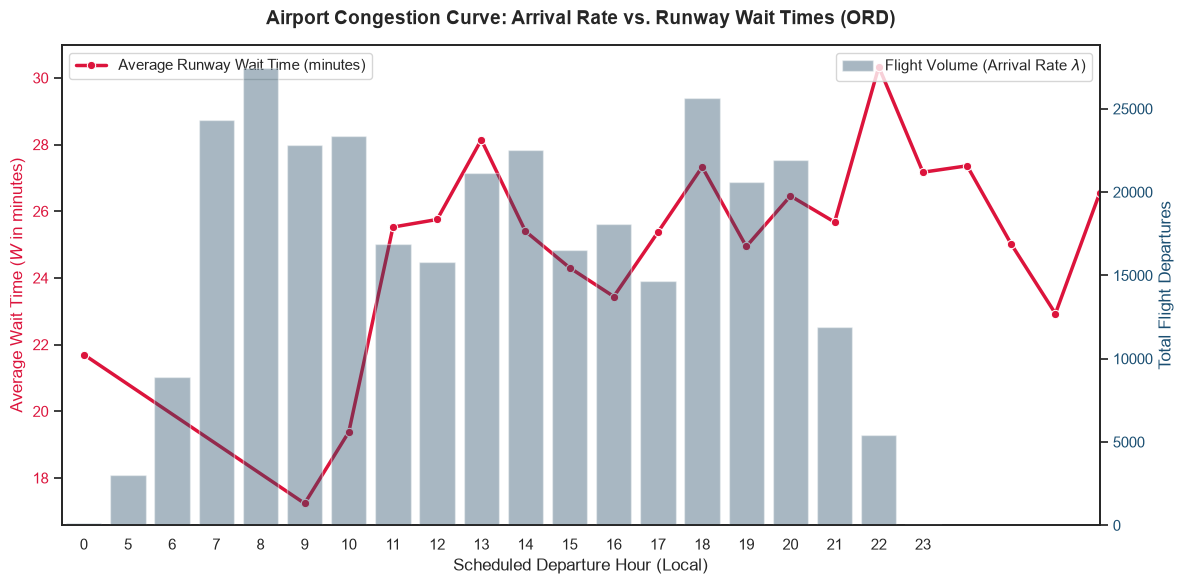

In [59]:
target_hub = 'ORD' # Chicago O'Hare International Airport

print(f"\nNow analyzing departures from {target_hub}...")

hub_flights = active_flights[active_flights['Origin'] == target_hub].copy()
print(f"Total active departures from {target_hub}: {len(hub_flights)}")

hub_flights['TaxiOut_clean'] = pd.to_numeric(hub_flights['TaxiOut'], errors='coerce').fillna(0)

# Get Arrival rate (lambda) and average wait time (W)
hourly_wait = hub_flights.groupby('DepHour').agg(
    ArrivalRate = ('FlightDate', 'count'), # Lambda
    AvgWaitTime = ('TaxiOut_clean', 'mean') # W
).reset_index()

sns.set_theme(style="white")
fig, ax1 = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=hourly_wait, 
    x='DepHour', 
    y='AvgWaitTime', 
    marker = 'o',
    color = 'crimson',
    ax=ax1,
    linewidth=2.5,
    label='Average Runway Wait Time (minutes)'
)

ax1.set_title(f'Airport Congestion Curve: Arrival Rate vs. Runway Wait Times ({target_hub})', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Scheduled Departure Hour (Local)', fontsize=12)
ax1.set_ylabel('Average Wait Time ($W$ in minutes)', fontsize=12, color='crimson')
ax1.tick_params(axis='y', labelcolor='crimson')
ax1.grid(False)

ax2 = ax1.twinx()
sns.barplot(
    data=hourly_wait, 
    x='DepHour', 
    y='ArrivalRate', 
    alpha=0.4, 
    color='#1B4F72', 
    ax=ax2, 
    label='Flight Volume (Arrival Rate $\lambda$)'
)
ax2.set_ylabel('Total Flight Departures', fontsize=12, color='#1B4F72')
ax2.tick_params(axis='y', labelcolor='#1B4F72')
ax2.grid(False)

plt.xticks(range(0, 24))
fig.tight_layout()
plt.show()

In [64]:
# DFW summary generated
hub_flights_dfw = active_flights[active_flights['Origin'] == 'DFW'].copy()
hub_flights_dfw['TaxiOut_clean'] = pd.to_numeric(hub_flights_dfw['TaxiOut'], errors='coerce').fillna(0)
hourly_wait_dfw = hub_flights_dfw.groupby('DepHour').agg(
    ArrivalRate=('FlightDate', 'count'),
    AvgWaitTime=('TaxiOut_clean', 'mean')
).reset_index()
hourly_wait_dfw['Hub'] = 'DFW'

# ORD summary generated
hub_flights_ord = active_flights[active_flights['Origin'] == 'ORD'].copy()
hub_flights_ord['TaxiOut_clean'] = pd.to_numeric(hub_flights_ord['TaxiOut'], errors='coerce').fillna(0)
hourly_wait_ord = hub_flights_ord.groupby('DepHour').agg(
    ArrivalRate=('FlightDate', 'count'),
    AvgWaitTime=('TaxiOut_clean', 'mean')
).reset_index()
hourly_wait_ord['Hub'] = 'ORD'

display(hourly_wait_dfw.head(10))
display(hourly_wait_ord.head(10))

,DepHour,ArrivalRate,AvgWaitTime,Hub
0,5,3845,15.859298,DFW
1,6,4753,17.345887,DFW
2,7,20685,20.105004,DFW
3,8,30687,21.623163,DFW
4,9,10955,18.344044,DFW
5,10,24835,21.301188,DFW
6,11,12758,18.006741,DFW
7,12,24908,19.546652,DFW
8,13,12272,16.974576,DFW
9,14,21166,18.412312,DFW


,DepHour,ArrivalRate,AvgWaitTime,Hub
0,0,110,21.700000,ORD
1,5,3034,17.234674,ORD
2,6,8900,19.377640,ORD
3,7,24347,25.524541,ORD
4,8,27456,25.752586,ORD
5,9,22849,28.142588,ORD
6,10,23381,25.397417,ORD
7,11,16857,24.304977,ORD
8,12,15827,23.441019,ORD
9,13,21155,25.373718,ORD


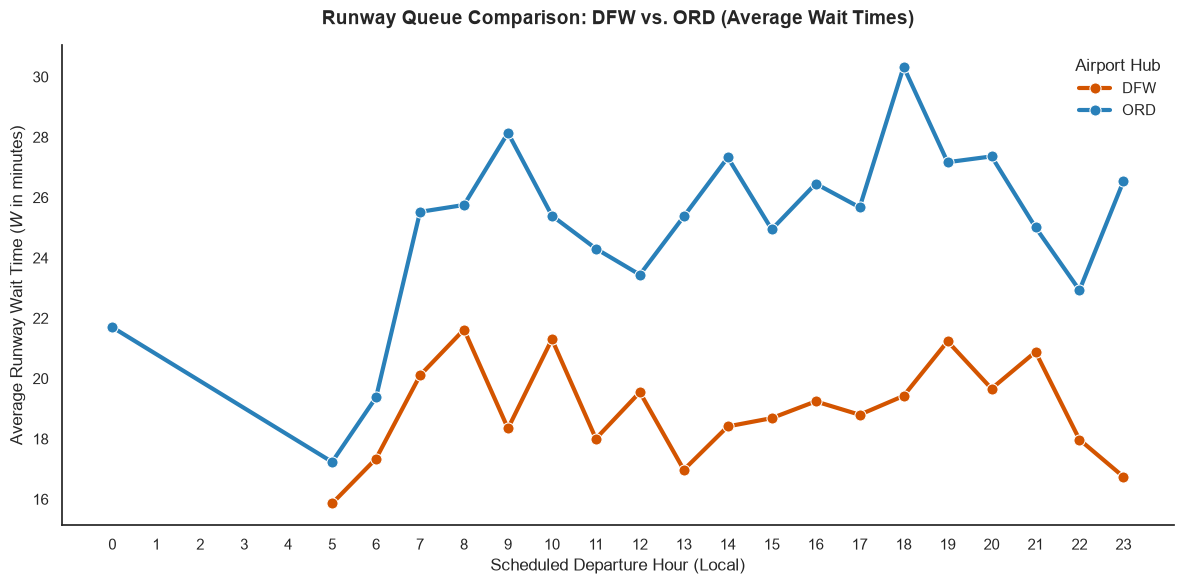

In [66]:
# Summary dataframe for both hubs
combined_hubs = pd.concat([hourly_wait_dfw, hourly_wait_ord])

# Direct comparison of average wait times between DFW and ORD
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=combined_hubs, 
    x='DepHour', 
    y='AvgWaitTime', 
    hue='Hub', 
    marker='o', 
    markersize=8,
    linewidth=3,
    palette={'DFW': '#D35400', 'ORD': '#2980B9'} # DFW in dark orange, ORD in deep blue
)

sns.despine(left=False, bottom=False)
ax.legend(frameon=False, title='Airport Hub', fontsize=11, title_fontsize=12)

ax.set_title('Runway Queue Comparison: DFW vs. ORD (Average Wait Times)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Scheduled Departure Hour (Local)', fontsize=12)
ax.set_ylabel('Average Runway Wait Time ($W$ in minutes)', fontsize=12)
ax.grid(False)

plt.xticks(range(0, 24))
fig.tight_layout()
plt.show()

In [70]:
num_days = active_flights['FlightDate'].nunique() # Total number of days in the dataset

runway_capacity_per_hour = 40 # Standard FAA optimal benchmark per runway (~40 operations/hr)

hub_configs = {
    'DFW': {'df': hourly_wait_dfw, 'runways': 3},
    'ORD': {'df': hourly_wait_ord, 'runways': 3} # Or 4 depending on configuration
}

print("=" * 45)
print("Peak Queue Utilization Metrics (rho = \lambda / c*mu$)")
print("=" * 45)

for hub_name, config in hub_configs.items():
    df = config['df']
    runways = config['runways']
    
    # Find peak hour row
    peak_row = df.loc[df['ArrivalRate'].idxmax()]
    lambda_total = peak_row['ArrivalRate']
    lambda_peak = lambda_total / num_days # true average arrival rate per hour
    avg_wait_peak = peak_row['AvgWaitTime']
    
    total_capacity = runways * runway_capacity_per_hour
    rho = lambda_peak / total_capacity
    
    print(f"[{hub_name}]")
    print(f"  - Active Departure Runways ($c$): {runways}")
    print(f"  - Peak Arrival Rate ($\lambda$): {lambda_peak:.1f} flights/hr (Hour {int(peak_row['DepHour'])}:00)")
    print(f"  - Peak Wait Time ($W$): {avg_wait_peak:.2f} minutes")
    print(f"  - Traffic Intensity (rho$): {rho:.2f}")
    
    if rho >= 1.0:
        print(f"  - Status: Oversaturated (rho >= 1.0$) — Queue grows exponentially.")
    else:
        print(f"  - Status: Sub-critical queue (Operating under theoretical capacity).")
    print("-" * 45)

Peak Queue Utilization Metrics (rho = \lambda / c*mu$)
[DFW]
  - Active Departure Runways ($c$): 3
  - Peak Arrival Rate ($\lambda$): 84.1 flights/hr (Hour 8:00)
  - Peak Wait Time ($W$): 21.62 minutes
  - Traffic Intensity (rho$): 0.70
  - Status: Sub-critical queue (Operating under theoretical capacity).
---------------------------------------------
[ORD]
  - Active Departure Runways ($c$): 3
  - Peak Arrival Rate ($\lambda$): 75.2 flights/hr (Hour 8:00)
  - Peak Wait Time ($W$): 25.75 minutes
  - Traffic Intensity (rho$): 0.63
  - Status: Sub-critical queue (Operating under theoretical capacity).
---------------------------------------------


<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/var/folders/7n/_bph8q656mz7td_1n564qw_40000gn/T/ipykernel_52305/559749754.py:11: SyntaxWarning: invalid escape sequence '\l'
  print("Peak Queue Utilization Metrics (rho = \lambda / c*mu$)")
/var/folders/7n/_bph8q656mz7td_1n564qw_40000gn/T/ipykernel_52305/559749754.py:29: SyntaxWarning: invalid escape sequence '\l'
  print(f"  - Peak Arrival Rate ($\lambda$): {lambda_peak:.1f} flights/hr (Hour {int(peak_row['DepHour'])}:00)")


<>:43: SyntaxWarning: invalid escape sequence '\l'
<>:57: SyntaxWarning: invalid escape sequence '\l'
<>:43: SyntaxWarning: invalid escape sequence '\l'
<>:57: SyntaxWarning: invalid escape sequence '\l'
/var/folders/7n/_bph8q656mz7td_1n564qw_40000gn/T/ipykernel_52305/3747460360.py:43: SyntaxWarning: invalid escape sequence '\l'
  print("Peak Queue Utilization Metrics (rho = \lambda / c*mu$)")
/var/folders/7n/_bph8q656mz7td_1n564qw_40000gn/T/ipykernel_52305/3747460360.py:57: SyntaxWarning: invalid escape sequence '\l'
  print(f"  - Peak Arrival Rate ($\lambda$): {lambda_peak} flights/hr at hour {int(peak_row['DepHour'])}")


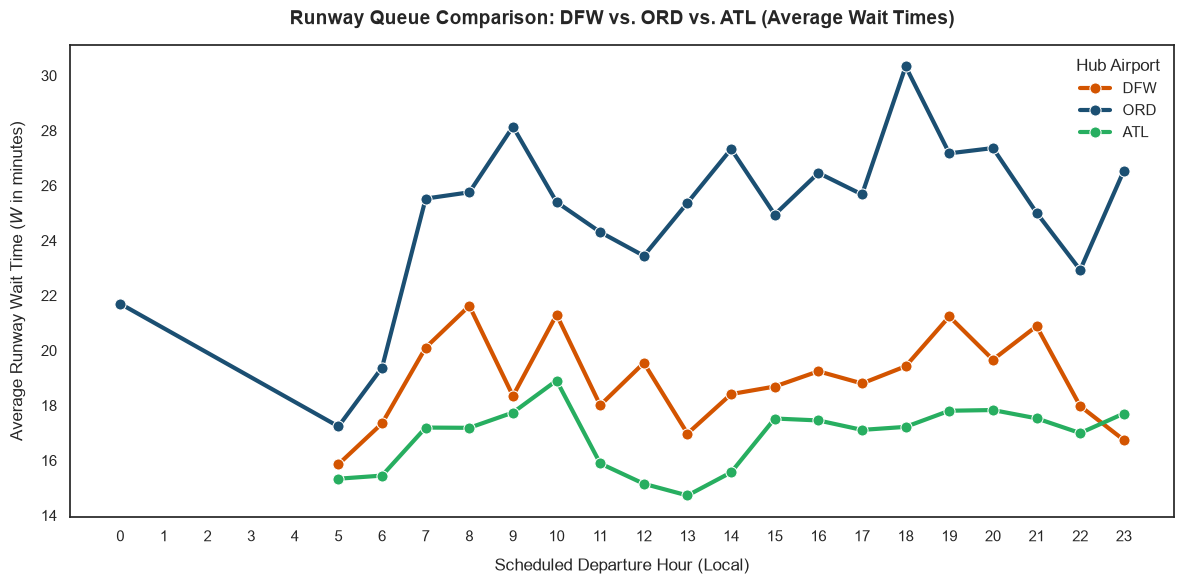

Peak Queue Utilization Metrics (rho = \lambda / c*mu$)
[DFW]
  - Active Departure Runways ($c$): 3
  - Peak Arrival Rate ($\lambda$): 30687 flights/hr at hour 8
  - Traffic Intensity (rho$): 255.72
  - Status: Oversaturated (rho > 1.0$) — Queue will grow exponentially.
---------------------------------------------
[ORD]
  - Active Departure Runways ($c$): 3
  - Peak Arrival Rate ($\lambda$): 27456 flights/hr at hour 8
  - Traffic Intensity (rho$): 228.80
  - Status: Oversaturated (rho > 1.0$) — Queue will grow exponentially.
---------------------------------------------
[ATL]
  - Active Departure Runways ($c$): 4
  - Peak Arrival Rate ($\lambda$): 24430 flights/hr at hour 8
  - Traffic Intensity (rho$): 152.69
  - Status: Oversaturated (rho > 1.0$) — Queue will grow exponentially.
---------------------------------------------


In [71]:
# ATL summary generated
hub_flights_atl = active_flights[active_flights['Origin'] == 'ATL'].copy()
hub_flights_atl['TaxiOut_clean'] = pd.to_numeric(hub_flights_atl['TaxiOut'], errors='coerce').fillna(0)
hourly_wait_atl = hub_flights_atl.groupby('DepHour').agg(
    ArrivalRate=('FlightDate', 'count'),
    AvgWaitTime=('TaxiOut_clean', 'mean')
).reset_index()
hourly_wait_atl['Hub'] = 'ATL'

# combined dataframe for all three hubs
combined_three_hubs = pd.concat([hourly_wait_dfw, hourly_wait_ord, hourly_wait_atl])

sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=combined_three_hubs, 
    x='DepHour', 
    y='AvgWaitTime', 
    hue='Hub', 
    marker='o', 
    markersize=8,
    linewidth=3,
    palette={
        'DFW': '#D35400', # Orange
        'ORD': '#1B4F72', # Blue
        'ATL': '#27AE60'  # Green
    }
)

ax.set_title('Runway Queue Comparison: DFW vs. ORD vs. ATL (Average Wait Times)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Scheduled Departure Hour (Local)', fontsize=12, labelpad=10)
ax.set_ylabel('Average Runway Wait Time ($W$ in minutes)', fontsize=12, labelpad=10)
ax.legend(frameon=False, title='Hub Airport', fontsize=11, title_fontsize=12)
ax.grid(False)

plt.xticks(range(0, 24))
fig.tight_layout()
plt.show()

# printing peak queue utilization metrics for all three hubs
print("=" * 45)
print("Peak Queue Utilization Metrics (rho = \lambda / c*mu$)")
print("=" * 45)

hub_data_dict = {'DFW': (hourly_wait_dfw, 3), 'ORD': (hourly_wait_ord, 3), 'ATL': (hourly_wait_atl, 4)}
runway_capacity_per_hour = 40 # Standard FAA benchmark

for hub_name, (df, runways) in hub_data_dict.items():
    peak_row = df.loc[df['ArrivalRate'].idxmax()]
    lambda_peak = peak_row['ArrivalRate']
    total_capacity = runways * runway_capacity_per_hour
    rho = lambda_peak / total_capacity
    
    print(f"[{hub_name}]")
    print(f"  - Active Departure Runways ($c$): {runways}")
    print(f"  - Peak Arrival Rate ($\lambda$): {lambda_peak} flights/hr at hour {int(peak_row['DepHour'])}")
    print(f"  - Traffic Intensity (rho$): {rho:.2f}")
    if rho >= 1.0:
        print(f"  - Status: Oversaturated (rho > 1.0$) — Queue will grow exponentially.")
    else:
        print(f"  - Status: Stable sub-critical queue.")
    print("-" * 45)

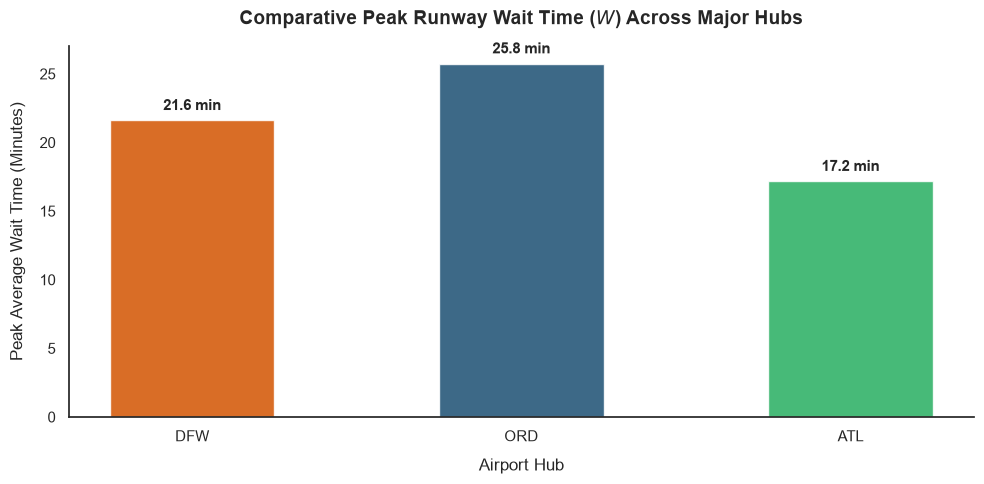


FINAL QUANTITATIVE QUEUING SUMMARY TABLE
Hub  PeakWaitTime  TrafficIntensity  PeakArrivalRate
DFW     21.623163          0.700616        84.073973
ORD     25.752586          0.626849        75.221918
ATL     17.185100          0.334658        66.931507


In [72]:
# compiled summary statistics for the three hubs
summary_data = []
num_days = active_flights['FlightDate'].nunique()
runway_capacity_per_hour = 40

hub_configs = {
    'DFW': {'df': hourly_wait_dfw, 'runways': 3},
    'ORD': {'df': hourly_wait_ord, 'runways': 3},
    'ATL': {'df': hourly_wait_atl, 'runways': 5} # ATL has 5 primary departure configuration options typically
}

for hub_name, config in hub_configs.items():
    df = config['df']
    runways = config['runways']
    
    peak_row = df.loc[df['ArrivalRate'].idxmax()]
    lambda_peak = peak_row['ArrivalRate'] / num_days
    avg_wait_peak = peak_row['AvgWaitTime']
    rho = lambda_peak / (runways * runway_capacity_per_hour)
    
    summary_data.append({
        'Hub': hub_name,
        'PeakWaitTime': avg_wait_peak,
        'TrafficIntensity': rho,
        'PeakArrivalRate': lambda_peak
    })

summary_df = pd.DataFrame(summary_data)

# comparartive bar chart for peak wait times across the three hubs
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    summary_df['Hub'], 
    summary_df['PeakWaitTime'], 
    color=['#D35400', '#1B4F72', '#27AE60'], 
    width=0.5,
    alpha=0.85
)

ax.set_title('Comparative Peak Runway Wait Time ($W$) Across Major Hubs', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Airport Hub', fontsize=12, labelpad=10)
ax.set_ylabel('Peak Average Wait Time (Minutes)', fontsize=12, labelpad=10)
ax.grid(False)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f} min',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), 
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold', fontsize=11)

sns.despine(left=False, bottom=False)
fig.tight_layout()
plt.show()

print("\n" + "=" * 55)
print("FINAL QUANTITATIVE QUEUING SUMMARY TABLE")
print("=" * 55)
print(summary_df.to_string(index=False))
print("=" * 55)